In [1]:
import os
import sys
import certifi
from dotenv import load_dotenv
# Add project root to path so we can import mcp_client
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname("__file__"), "..")))
load_dotenv()
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
from typing import Any, TypedDict, Annotated
import operator
import uuid
import asyncio
import json
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import Command, interrupt
from langchain_core.messages import (
    AnyMessage,
    HumanMessage,
    AIMessage,
    SystemMessage,
)
from langchain_openai import ChatOpenAI
from mcp_client import (           # ← plain import now works
    tavily_mcp_search,
    aviation_mcp_call,
    extract_destination,
    forecast_mcp_search,
    weather_mcp_search,
)

In [2]:
from pathlib import Path

# Explicitly point to the project root .env
dotenv_path = Path(__file__ if '__file__' in dir() else '.').resolve().parent.parent / '.env'
# Or just hardcode it to be safe:
load_dotenv(r"D:\PIS\youtube\TripMate-Multi-Agent-AI-System\.env", override=True)

True

In [3]:
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
TYPESAFE_API_KEY=os.getenv("TYPESAFE_API_KEY")

if not OPENAI_API_KEY:
    raise ValueError("OPENAI_API_KEY is missing. Please add it to your .env file.")

# =========================
# LLM
# =========================
llm = ChatOpenAI(
    model="gpt-5-mini",
    api_key=OPENAI_API_KEY,
)


In [4]:
llm.invoke("hello")

AIMessage(content='Hello! How can I help you today? (You can ask a question, request writing/code help, get a summary or translation, or anything else.)', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 104, 'prompt_tokens': 7, 'total_tokens': 111, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Eb1RJGaYp9arA06ANEfTBvqCd23Mc', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a158df-18da-7cf0-8eb4-7badda4011f4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7, 'output_tokens': 104, 'total_tokens': 111, 'input_token_details': {

In [5]:
# =========================
# State - original fields kept, new control fields added
# =========================
class TravelState(TypedDict, total=False):
    messages: Annotated[list[AnyMessage], operator.add]
    user_query: str

    # Supervisor + guardrail state
    guardrail_allowed: bool
    guardrail_reason: str
    selected_agents: list[str]
    trip_constraints: dict[str, Any]
    supervisor_reasoning: str

    # Original specialist results
    flight_results: str
    hotel_results: str
    weather_results: str
    itinerary: str

    # New budget + HITL state
    budget_results: str
    approval_request: str
    approved: bool
    human_feedback: str
    final_response: str

    llm_calls: int

In [6]:
# =========================
# Shared helpers
# =========================
KNOWN_AGENTS = {
    "flight_agent",
    "hotel_agent",
    "weather_agent",
    "budget_agent",
    "itinerary_agent",
}

AGENT_ORDER = [
    "flight_agent",
    "hotel_agent",
    "weather_agent",
    "budget_agent",
    "itinerary_agent",
]

In [7]:
def _llm_text(system_prompt: str, user_prompt: str) -> str:
    response = llm.invoke(
        [
            SystemMessage(content=system_prompt),
            HumanMessage(content=user_prompt),
        ]
    )
    return str(response.content)


In [8]:

def _json_from_llm(text: str) -> dict[str, Any]:
    """Extract the first complete JSON object returned by the model."""
    start = text.find("{")
    end = text.rfind("}")

    if start == -1 or end == -1 or end < start:
        raise ValueError("The model did not return a JSON object.")

    return json.loads(text[start : end + 1])


In [9]:
def _empty_constraints() -> dict[str, Any]:
    return {
        "destination": "",
        "origin": "",
        "duration": "",
        "budget": "",
        "travel_style": "",
        "special_preferences": [],
    }


In [11]:
from langchain_typesafe import Choice, Noul, Score, TypeSafeClassifier


In [18]:
from langchain_core.output_parsers import string

Jev_classifier = TypeSafeClassifier(
 model="jev-latest",
 api_key=os.environ["TYPESAFE_API_KEY"]
)

def jev_response(user_query: str , guardrail_prompt: str):

    response = Jev_classifier.invoke(
        {
            "state": (
                user_query,
            ),
            "questions": {
                "guardrail_Approval": Noul(instructions=guardrail_prompt)
            },
        }
    )

    print(response.nouls["guardrail_Approval"].noul)
    return response.nouls["guardrail_Approval"].noul >= 0.75



In [19]:
guardrail_prompt = """Determine whether the following request belongs to travel planning or travel
information. Valid requests can include destinations, flights, hotels, weather,
budgets, visas, transportation, sightseeing, food, packing, or itineraries.

Block clearly unrelated requests and requests asking for harmful or illegal
instructions. Do not block a valid travel request merely because some details
are missing. You need to classify if it is a valid request or not."""

In [20]:
user_query="""Plan a complete 7 days UAE trip from India including flights, hotels and sightseeing under 2 lakhs.
"""

In [21]:
jev_response(user_query, guardrail_prompt)

0.98


True

In [22]:
def guardrail_blocked_agent(state: TravelState):
    query = state["user_query"]
    llm_calls = state.get("llm_calls", 0)

    guardrail_prompt = """Determine whether the following request belongs to travel planning or travel
information. Valid requests can include destinations, flights, hotels, weather,
budgets, visas, transportation, sightseeing, food, packing, or itineraries.

Block clearly unrelated requests and requests asking for harmful or illegal
instructions. Do not block a valid travel request merely because some details
are missing. You need to classify if it is a valid request or not."""

    allowed = jev_response(query, guardrail_prompt)
    if allowed:
        reason = "approved"
    else:
        reason = """TripMate AI can only help with travel-planning requests.
            Please ask about a destination, flight, hotel, weather, budget,
            or itinerary."""

    return {
        "guardrail_allowed": allowed,  
        "guardrail_reason": reason,
        "llm_calls": llm_calls + 1,
        "messages": [AIMessage(content=reason)],    
    }


In [23]:
def supervisor_agent(state: TravelState):
    query = state["user_query"]
    llm_calls = state.get("llm_calls", 0)
    supervisor_prompt = f"""
You are the supervisor of a multi-agent travel-planning system.
Choose only the specialist agents needed for the request.

Available agents:
- flight_agent: flights, airports, airlines, routes, airfare, or booking advice
- hotel_agent: hotels, accommodation, neighborhoods, or places to stay
- weather_agent: weather, climate, season, forecast, or packing advice
- budget_agent: cost, affordability, price limits, or budget feasibility
- itinerary_agent: creates the integrated travel plan and must always be included

Return strict JSON only using this schema:
{{
  "selected_agents": ["flight_agent", "hotel_agent", "weather_agent", "budget_agent", "itinerary_agent"],
  "trip_constraints": {{
    "destination": "",
    "origin": "",
    "duration": "",
    "budget": "",
    "travel_style": "",
    "special_preferences": []
  }},
  "reasoning": ""
}}

User request:
{query}
"""

    try:
        supervisor_raw = _llm_text(
            "You route work to travel specialist agents. Return strict JSON only.",
            supervisor_prompt,
        )
        parsed = _json_from_llm(supervisor_raw)
        requested_agents = parsed.get("selected_agents", [])
        selected_agents = [
            name for name in AGENT_ORDER
            if name in requested_agents and name in KNOWN_AGENTS
        ]

        # The itinerary agent integrates whichever specialist results were selected.
        if "itinerary_agent" not in selected_agents:
            selected_agents.append("itinerary_agent")

        constraints = _empty_constraints()
        parsed_constraints = parsed.get("trip_constraints", {})
        if isinstance(parsed_constraints, dict):
            constraints.update(parsed_constraints)

        reasoning = str(parsed.get("reasoning", "")).strip()
        llm_calls += 1
    except Exception as exc:
        print(f"Supervisor fallback used: {exc}")
        # Original workflow behavior is preserved as the fallback.
        selected_agents = AGENT_ORDER.copy()
        constraints = _empty_constraints()
        reasoning = (
            "Supervisor parsing failed, so the original full travel workflow "
            "was selected as a safe fallback."
        )

    return {
        "selected_agents": selected_agents,
        "trip_constraints": constraints,
        "supervisor_reasoning": reasoning,
        "messages": [AIMessage(content="Supervisor created the agent plan.")],
        "llm_calls": llm_calls + 1,
    }

In [24]:
# =========================
# Flight Agent - original behavior kept
# =========================
FLIGHT_AGENT_PROMPT = """
You are a travel flight expert.

User Query:
{query}

Airport Information:
{airport_data}

Airline Information:
{airline_data}

Generate:
1. Likely departure airport
2. Likely arrival airport
3. Airlines serving this route
4. Typical flight duration
5. Estimated airfare range
6. Peak season pricing warning
7. Booking advice

Return concise travel guidance.
"""


def flight_agent(state: TravelState):
    print("\nINSIDE FLIGHT AGENT\n")
    query = state["user_query"]

    try:
        airports = asyncio.run(aviation_mcp_call("list_airports"))
        airlines = asyncio.run(aviation_mcp_call("list_airlines"))

        print("\nAIRPORTS:", airports)
        print("\nAIRLINES:", airlines)

        prompt = FLIGHT_AGENT_PROMPT.format(
            query=query,
            airport_data=str(airports)[:3000],
            airline_data=str(airlines)[:3000],
        )

        response = llm.invoke(
            [
                SystemMessage(content="You are an expert travel flight planner."),
                HumanMessage(content=prompt),
            ]
        )
        flight_data = response.content
    except Exception as exc:
        flight_data = f"Flight information unavailable: {exc}"

    return {
        "flight_results": flight_data,
        "messages": [AIMessage(content="Flight recommendations generated")],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }



In [25]:
# =========================
# Hotel Agent - original behavior kept
# =========================
def hotel_agent(state: TravelState):
    query = (
        f"Best hotels for "
        f"{state['user_query']}"
    )

    try:
        hotel_results = asyncio.run(
            tavily_mcp_search(query)
        )

    except Exception as exc:
        print(
            f"HOTEL AGENT MCP ERROR: "
            f"{type(exc).__name__}: {exc}",
            flush=True,
        )

        hotel_results = (
            "Live hotel search is temporarily unavailable. "
            "Provide general accommodation and neighborhood "
            "guidance based on the destination and clearly "
            "label it as non-live advice."
        )

    return {
        "hotel_results": hotel_results,
        "messages": [
            AIMessage(
                content="Hotel information processed."
            )
        ],
        "llm_calls": (
            state.get("llm_calls", 0) + 1
        ),
    }



In [26]:

# =========================
# Weather Agent - original behavior kept
# =========================
def weather_agent(state: TravelState):
    city = extract_destination(
        state["user_query"]
    )

    try:
        weather_data = asyncio.run(
            weather_mcp_search(city)
        )

        forecast_data = asyncio.run(
            forecast_mcp_search(city)
        )

        weather_results = f"""
Current Weather:
{weather_data}

Forecast:
{forecast_data}
"""

    except Exception as exc:
        print(
            f"WEATHER AGENT MCP ERROR: "
            f"{type(exc).__name__}: {exc}",
            flush=True,
        )

        weather_results = (
            f"Live weather information for {city} "
            "is temporarily unavailable. Give general "
            "seasonal guidance and advise the traveler "
            "to verify the forecast before departure."
        )

    return {
        "weather_results": weather_results,
        "messages": [
            AIMessage(
                content="Weather information processed."
            )
        ],
    }

In [27]:
# =========================
# Budget Agent - new specialist
# =========================
def budget_agent(state: TravelState):
    prompt = f"""
Analyze whether this trip is realistic for the user's budget.

User Query:
{state['user_query']}

Trip Constraints:
{state.get('trip_constraints', {})}

Flight Results:
{state.get('flight_results', '')}

Hotel Results:
{state.get('hotel_results', '')}

Weather Results:
{state.get('weather_results', '')}

Return:
1. Estimated cost categories
2. Budget risk areas
3. Money-saving suggestions
4. Overall feasibility

If exact live prices are unavailable, clearly label estimates as approximate.
"""

    response = llm.invoke(
        [
            SystemMessage(content="You are a practical travel budget analyst."),
            HumanMessage(content=prompt),
        ]
    )

    return {
        "budget_results": response.content,
        "messages": [AIMessage(content="Budget assessment generated.")],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }


In [28]:
# =========================
# Itinerary Agent - original behavior extended with selected results
# =========================
def itinerary_agent(state: TravelState):
    prompt = f"""
Create a complete travel itinerary.

User Query:
{state['user_query']}

Trip Constraints:
{state.get('trip_constraints', {})}

Flight Results:
{state.get('flight_results', '')}

Hotel Results:
{state.get('hotel_results', '')}

Weather Results:
{state.get('weather_results', '')}

Budget Results:
{state.get('budget_results', '')}

Make the itinerary practical, budget-aware, and easy to follow.
Create a clear draft that is ready for human review.
"""

    response = llm.invoke(
        [
            SystemMessage(content="You are an expert travel planner."),
            HumanMessage(content=prompt),
        ]
    )

    approval_request = (
        "Please review the generated draft itinerary. Approve it to create the "
        "final polished plan, or provide feedback for revision."
    )

    return {
        "itinerary": response.content,
        "approval_request": approval_request,
        "messages": [AIMessage(content="Draft itinerary created for human review.")],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }

In [29]:
def human_approval_agent(state: TravelState):
    # Do not wrap interrupt() in try/except. LangGraph uses it to pause execution.
    review = interrupt(
        {
            "question": "Do you approve this itinerary?",
            "draft_itinerary": state.get("itinerary", ""),
            "approval_request": state.get("approval_request", ""),
            "selected_agents": state.get("selected_agents", []),
            "supervisor_reasoning": state.get("supervisor_reasoning", ""),
            "expected_response": {
                "approved": True,
                "feedback": "Optional revision feedback",
            },
        }
    )

    approved = bool(review.get("approved", False))
    human_feedback = str(review.get("feedback", "")).strip()

    return {
        "approved": approved,
        "human_feedback": human_feedback,
        "messages": [AIMessage(content="Human approval step completed.")],
    }

In [30]:
def final_agent(state: TravelState):
    if state.get("approved", False):
        review_instruction = (
            "The user approved the draft. Preserve its decisions while polishing it."
        )
    else:
        review_instruction = f"""
The user requested a revision. Apply this feedback carefully:
{state.get('human_feedback', '') or 'Improve the draft before finalizing it.'}
"""

    final_prompt = f"""
Generate the final travel response for the user.

Human Review:
{review_instruction}

User Request:
{state['user_query']}

Supervisor Constraints:
{state.get('trip_constraints', {})}

Flights:
{state.get('flight_results', '')}

Hotels:
{state.get('hotel_results', '')}

Weather:
{state.get('weather_results', '')}

Budget Analysis:
{state.get('budget_results', '')}

Draft Itinerary:
{state.get('itinerary', '')}

Format the final answer beautifully using these sections:
1. Trip Summary
2. Flight Information
3. Hotel Suggestions
4. Weather Information
5. Day-by-Day Itinerary
6. Estimated Budget
7. Final Recommendations

Important:
- Be clear and practical.
- Mention that live flight APIs may not provide ticket prices when pricing is unavailable.
- Include weather-based travel advice.
- Keep the response useful for real travel planning.
- Incorporate the human feedback when revision was requested.
"""

    response = llm.invoke(
        [
            SystemMessage(
                content="You are a professional AI travel booking assistant."
            ),
            HumanMessage(content=final_prompt),
        ]
    )

    return {
        "final_response": response.content,
        "messages": [response],
        "llm_calls": state.get("llm_calls", 0) + 1,
    }


In [33]:
ROUTE_MAP = {
    "flight_agent": "flight_agent",
    "hotel_agent": "hotel_agent",
    "weather_agent": "weather_agent",
    "budget_agent": "budget_agent",
    "itinerary_agent": "itinerary_agent",
}

In [31]:
def _selected_agents(state: TravelState) -> list[str]:
    selected = state.get("selected_agents", [])
    return [agent for agent in AGENT_ORDER if agent in selected]


def route_from_supervisor(state: TravelState) -> str:
    if not state.get("guardrail_allowed", True):
        return "guardrail_blocked"

    selected = _selected_agents(state)
    return selected[0] if selected else "itinerary_agent"


def route_after_agent(current_agent: str):
    def route(state: TravelState) -> str:
        selected = _selected_agents(state)
        current_index = AGENT_ORDER.index(current_agent)

        for next_agent in AGENT_ORDER[current_index + 1 :]:
            if next_agent in selected:
                return next_agent

        return "itinerary_agent"

    return route


def guardrail_node_conditional_edges(state: TravelState) -> str:
    if not state.get("guardrail_allowed", True):
        return END
    return "supervisor"


In [34]:
# =========================
# Build Graph
# =========================
graph = StateGraph(TravelState)

graph.add_node("supervisor", supervisor_agent)
graph.add_node("guardrail", guardrail_blocked_agent)
graph.add_node("flight_agent", flight_agent)
graph.add_node("hotel_agent", hotel_agent)
graph.add_node("weather_agent", weather_agent)
graph.add_node("budget_agent", budget_agent)
graph.add_node("itinerary_agent", itinerary_agent)
graph.add_node("human_approval", human_approval_agent)
graph.add_node("final_agent", final_agent)

graph.add_edge(START, "guardrail")
graph.add_conditional_edges("guardrail", guardrail_node_conditional_edges, {
        "supervisor": "supervisor",
        END: END,
    } )
graph.add_conditional_edges("supervisor", route_from_supervisor, ROUTE_MAP)

graph.add_conditional_edges(
    "flight_agent", route_after_agent("flight_agent"), ROUTE_MAP
)
graph.add_conditional_edges(
    "hotel_agent", route_after_agent("hotel_agent"), ROUTE_MAP
)
graph.add_conditional_edges(
    "weather_agent", route_after_agent("weather_agent"), ROUTE_MAP
)
graph.add_conditional_edges(
    "budget_agent", route_after_agent("budget_agent"), ROUTE_MAP
)

graph.add_edge("itinerary_agent", "human_approval")
graph.add_edge("human_approval", "final_agent")
graph.add_edge("final_agent", END)

In [35]:
checkpointer = MemorySaver()

travel_graph = graph.compile(checkpointer=checkpointer)

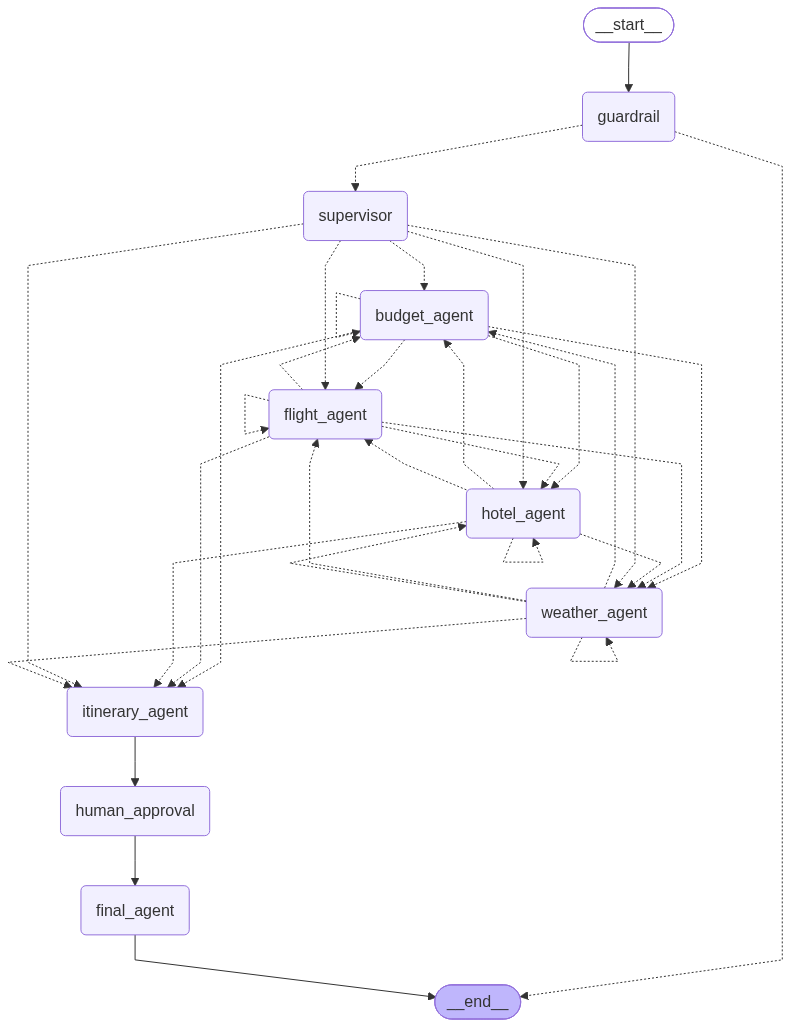

In [36]:
travel_graph